In [1]:
# 1. Imports and device
import copy
import gc
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


In [2]:
# 2. Locate Imagenette and load the datasets
base_dir = Path.cwd().resolve()
data_dir = next(
    (folder / "imagenette2-160" for folder in [base_dir, *base_dir.parents]
     if (folder / "imagenette2-160").exists()),
    None
)

if data_dir is None:
    raise FileNotFoundError("Could not find imagenette2-160. Set data_dir manually.")

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = datasets.ImageFolder(data_dir / "train", transform=train_transform)
val_dataset = datasets.ImageFolder(data_dir / "val", transform=val_transform)

class_ids = train_dataset.classes
assert class_ids == val_dataset.classes
assert len(class_ids) == 10

class_name_map = {
    "n01440764": "Tench",
    "n02102040": "English Springer",
    "n02979186": "Cassette Player",
    "n03000684": "Chain Saw",
    "n03028079": "Church",
    "n03394916": "French Horn",
    "n03417042": "Garbage Truck",
    "n03425413": "Gas Pump",
    "n03445777": "Golf Ball",
    "n03888257": "Parachute"
}
class_names = [class_name_map[class_id] for class_id in class_ids]

dataset_sizes = {
    "train": len(train_dataset),
    "val": len(val_dataset)
}

batch_size = 64
num_workers = 4

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=(device.type == "cuda"),
    persistent_workers=(num_workers > 0)
)

print("Dataset:", data_dir)
print("Classes:", class_names)
print("Training images:", dataset_sizes["train"])
print("Validation images:", dataset_sizes["val"])


Dataset: C:\Users\radun\Desktop\Artificial-Intelligence-Masters\Neural Networks (NN)\Homework\HW1\imagenette2-160
Classes: ['Tench', 'English Springer', 'Cassette Player', 'Chain Saw', 'Church', 'French Horn', 'Garbage Truck', 'Gas Pump', 'Golf Ball', 'Parachute']
Training images: 9469
Validation images: 3925


In [3]:
# 3. Reproducibility and model creation
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def create_model():
    model = models.resnet18(
        weights=models.ResNet18_Weights.IMAGENET1K_V1
    )

    for parameter in model.parameters():
        parameter.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, len(class_names))
    return model.to(device)


In [4]:
# 4. Train and validate one configuration
def train_model(adapt_bn_stats, num_epochs=25, seed=42):
    set_seed(seed)

    train_generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=(device.type == "cuda"),
        persistent_workers=(num_workers > 0),
        generator=train_generator
    )

    model = create_model()
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        model.fc.parameters(),
        lr=0.001,
        momentum=0.9
    )
    scheduler = lr_scheduler.StepLR(
        optimizer,
        step_size=7,
        gamma=0.1
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "epoch_time": []
    }

    best_acc = 0.0
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())
    start_time = time.perf_counter()

    for epoch in range(num_epochs):
        epoch_start = time.perf_counter()

        for phase in ["train", "val"]:
            if phase == "train":
                model.train()
                if not adapt_bn_stats:
                    for module in model.modules():
                        if isinstance(module, nn.BatchNorm2d):
                            module.eval()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in (train_loader if phase == "train" else val_loader):
                inputs = inputs.to(device)
                labels = labels.to(device)

                if phase == "train":
                    optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    predictions = outputs.argmax(dim=1)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += (predictions == labels).sum().item()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects / dataset_sizes[phase]

            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)

            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_epoch = epoch + 1
                best_weights = copy.deepcopy(model.state_dict())

        scheduler.step()

        if device.type == "cuda":
            torch.cuda.synchronize()

        epoch_time = time.perf_counter() - epoch_start
        history["epoch_time"].append(epoch_time)

        print(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"Train Loss: {history['train_loss'][-1]:.4f} | "
            f"Train Acc: {history['train_acc'][-1]:.2%} | "
            f"Val Loss: {history['val_loss'][-1]:.4f} | "
            f"Val Acc: {history['val_acc'][-1]:.2%} | "
            f"Time: {epoch_time:.2f}s"
        )

    model.load_state_dict(best_weights)
    total_time = time.perf_counter() - start_time
    del train_loader
    gc.collect()

    return model, history, best_acc, best_epoch, total_time


In [5]:
# 5. Train and save frozen-BN and adapted-BN models
epochs = 25

print("EXPERIMENT 1: FROZEN BATCHNORM")
model_frozen, history_frozen, best_acc_frozen, epoch_frozen, time_frozen = train_model(
    adapt_bn_stats=False,
    num_epochs=epochs,
    seed=42
)
torch.save(model_frozen.state_dict(), "resnet18_frozen_bn.pth")
del model_frozen
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()

print("\nEXPERIMENT 2: ADAPTED BATCHNORM")
model_adapted, history_adapted, best_acc_adapted, epoch_adapted, time_adapted = train_model(
    adapt_bn_stats=True,
    num_epochs=epochs,
    seed=42
)
torch.save(model_adapted.state_dict(), "resnet18_adapted_bn.pth")
del model_adapted
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()


EXPERIMENT 1: FROZEN BATCHNORM
Epoch 1/25 | Train Loss: 0.8542 | Train Acc: 79.11% | Val Loss: 0.2423 | Val Acc: 95.52% | Time: 23.21s
Epoch 2/25 | Train Loss: 0.3447 | Train Acc: 92.03% | Val Loss: 0.1691 | Val Acc: 96.36% | Time: 3.77s
Epoch 3/25 | Train Loss: 0.2865 | Train Acc: 92.74% | Val Loss: 0.1413 | Val Acc: 96.56% | Time: 3.76s
Epoch 4/25 | Train Loss: 0.2687 | Train Acc: 92.73% | Val Loss: 0.1262 | Val Acc: 97.02% | Time: 3.70s
Epoch 5/25 | Train Loss: 0.2510 | Train Acc: 93.18% | Val Loss: 0.1160 | Val Acc: 97.02% | Time: 3.71s
Epoch 6/25 | Train Loss: 0.2387 | Train Acc: 93.07% | Val Loss: 0.1090 | Val Acc: 97.10% | Time: 3.75s
Epoch 7/25 | Train Loss: 0.2358 | Train Acc: 93.18% | Val Loss: 0.1059 | Val Acc: 97.07% | Time: 3.74s
Epoch 8/25 | Train Loss: 0.2272 | Train Acc: 93.36% | Val Loss: 0.1037 | Val Acc: 97.12% | Time: 3.66s
Epoch 9/25 | Train Loss: 0.2289 | Train Acc: 93.46% | Val Loss: 0.1028 | Val Acc: 97.07% | Time: 3.67s
Epoch 10/25 | Train Loss: 0.2322 | Train 

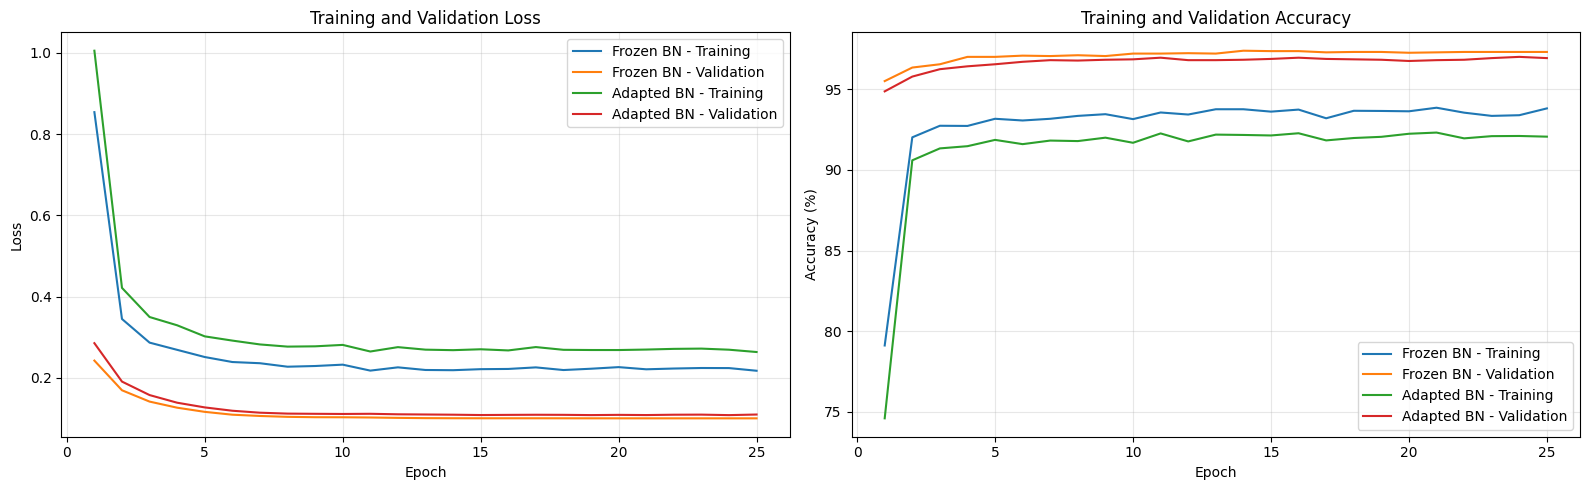

In [6]:
# 6. Plot loss and accuracy curves
epoch_range = range(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(epoch_range, history_frozen["train_loss"], label="Frozen BN - Training")
axes[0].plot(epoch_range, history_frozen["val_loss"], label="Frozen BN - Validation")
axes[0].plot(epoch_range, history_adapted["train_loss"], label="Adapted BN - Training")
axes[0].plot(epoch_range, history_adapted["val_loss"], label="Adapted BN - Validation")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epoch_range, np.array(history_frozen["train_acc"]) * 100, label="Frozen BN - Training")
axes[1].plot(epoch_range, np.array(history_frozen["val_acc"]) * 100, label="Frozen BN - Validation")
axes[1].plot(epoch_range, np.array(history_adapted["train_acc"]) * 100, label="Adapted BN - Training")
axes[1].plot(epoch_range, np.array(history_adapted["val_acc"]) * 100, label="Adapted BN - Validation")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
# 7. Compare frozen and adapted BatchNorm
comparison = pd.DataFrame([
    {
        "Configuration": "Frozen BatchNorm",
        "Best validation accuracy": best_acc_frozen,
        "Best epoch": epoch_frozen,
        "Final validation accuracy": history_frozen["val_acc"][-1],
        "Average epoch time (s)": np.mean(history_frozen["epoch_time"])
    },
    {
        "Configuration": "Adapted BatchNorm",
        "Best validation accuracy": best_acc_adapted,
        "Best epoch": epoch_adapted,
        "Final validation accuracy": history_adapted["val_acc"][-1],
        "Average epoch time (s)": np.mean(history_adapted["epoch_time"])
    }
])

display(comparison.style.format({
    "Best validation accuracy": "{:.2%}",
    "Final validation accuracy": "{:.2%}",
    "Average epoch time (s)": "{:.2f}"
}))

difference = (best_acc_adapted - best_acc_frozen) * 100
if difference > 0:
    print(f"Adapted BatchNorm improved best validation accuracy by {difference:.2f} percentage points.")
elif difference < 0:
    print(f"Adapted BatchNorm reduced best validation accuracy by {abs(difference):.2f} percentage points.")



,Configuration,Best validation accuracy,Best epoch,Final validation accuracy,Average epoch time (s)
0,Frozen BatchNorm,97.40%,14,97.32%,4.50
1,Adapted BatchNorm,97.02%,24,96.94%,4.19


Adapted BatchNorm reduced best validation accuracy by 0.38 percentage points.


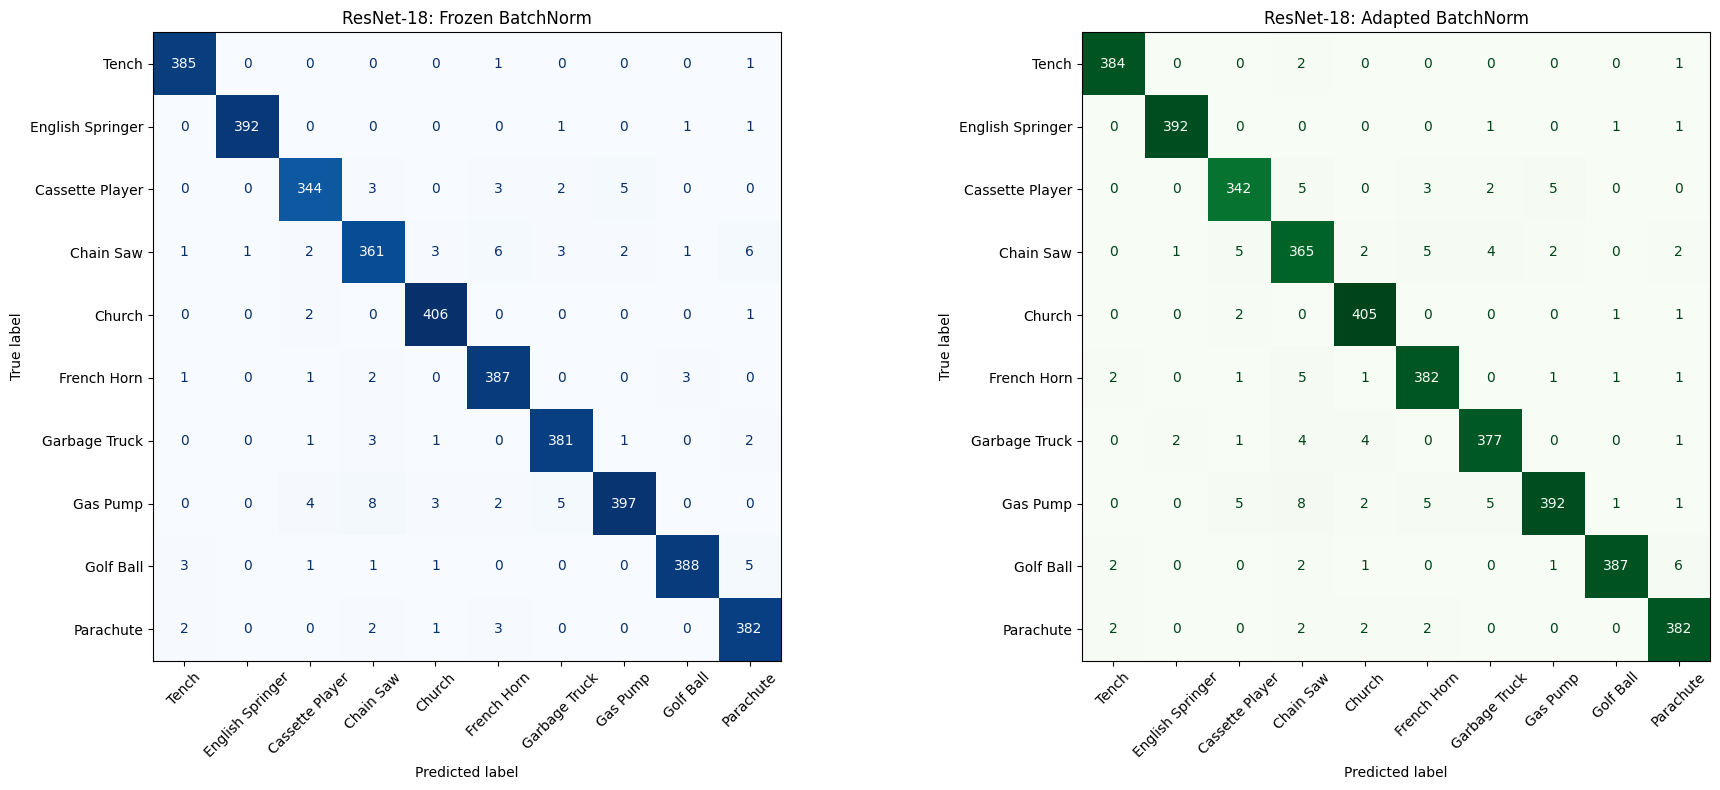

In [9]:
# 8. Evaluate ResNet-18 and plot confusion matrices
def evaluate_model(model, loader):
    model.eval()
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            predictions = outputs.argmax(dim=1)
            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())

    return all_labels, all_predictions


model_frozen = create_model()
model_frozen.load_state_dict(torch.load("resnet18_frozen_bn.pth", map_location=device, weights_only=True))
true_frozen, pred_frozen = evaluate_model(model_frozen, val_loader)

model_adapted = create_model()
model_adapted.load_state_dict(torch.load("resnet18_adapted_bn.pth", map_location=device, weights_only=True))
true_adapted, pred_adapted = evaluate_model(model_adapted, val_loader)

num_classes = len(class_names)
cm_frozen = confusion_matrix(true_frozen, pred_frozen, labels=range(num_classes))
cm_adapted = confusion_matrix(true_adapted, pred_adapted, labels=range(num_classes))

fig, axes = plt.subplots(1, 2, figsize=(19, 8))

ConfusionMatrixDisplay(cm_frozen, display_labels=class_names).plot(
    ax=axes[0], cmap="Blues", xticks_rotation=45, colorbar=False
)
axes[0].set_title("ResNet-18: Frozen BatchNorm")

ConfusionMatrixDisplay(cm_adapted, display_labels=class_names).plot(
    ax=axes[1], cmap="Greens", xticks_rotation=45, colorbar=False
)
axes[1].set_title("ResNet-18: Adapted BatchNorm")

plt.tight_layout()
plt.show()
